# **Project Name** - Financial Forecasting Frontier: Distributed ML
##### **Project Type** - Exploratory Data Analysis with Apache Spark
##### **Domain** - Banking & Financial Services
##### **Contribution** - Individual (Jignesh)


# **Project Summary**
In the modern commercial banking sector, large financial institutions process millions of multi-channel customer interactions every day. Traditional single-node data processing tools (such as single-threaded scripts or desktop spreadsheets) encounter memory bottlenecks and prohibitive latencies when managing high-volume data streams. This capstone module, **Financial Forecasting Frontier: Distributed ML (Part 2 - Exploratory Data Analysis with Apache Spark)**, demonstrates how Apache Spark leverages in-memory distributed computing, lazy evaluation Directed Acyclic Graphs (DAGs), and resilient distributed datasets to execute high-throughput analytics on banking data.

Using the `bank.csv` dataset (comprising 4,521 customer records across 17 demographic, financial, and marketing attributes), this project investigates customer liquidity, credit behavior, and campaign conversion drivers. Utilizing PySpark's DataFrame API and Spark SQL, we perform end-to-end data ingestion, schema validation, distributed transformations, custom User-Defined Functions (UDFs), and multi-dimensional aggregations.

Key findings from this distributed exploratory analysis include:
1. **Demographic Wealth Gradient**: Account balances rise significantly across age cohorts; clients over 60 hold an average balance of $2,676.35—nearly 2.5x higher than customers under 30 ($1,058.10).
2. **Occupational Liquidity & Risk**: Retired individuals ($2,319.19), housemaids ($2,083.80), and management personnel ($1,766.93) maintain the highest mean balances. Furthermore, entrepreneurs exhibit the highest credit default rate (4.17%), followed by unemployed (2.34%) and self-employed (2.19%) clients.
3. **Campaign Conversion Dynamics**: Overall term deposit subscription is 11.52%. Significant seasonal divergence is observed: May accounted for 30.9% of all outreach volume (1,398 contacts) yet yielded only a 6.65% conversion rate. In contrast, October (46.25%), December (45.00%), and March (42.86%) demonstrated superior conversion efficiency.
4. **Call Duration as a Conversion Indicator**: Clients who subscribed engaged in calls averaging 552.74 seconds (~9.2 minutes), compared to 226.35 seconds (~3.8 minutes) for non-subscribers.
This analysis establishes the empirical foundation for predictive modeling and real-time streaming architectures implemented in subsequent project phases.


# **Problem Statement**
A commercial banking institution seeks to optimize its direct telemarketing campaigns for term deposit products. Currently, marketing resources are dispersed uniformly across broad demographic segments, resulting in a low overall conversion rate (11.52%) and unnecessary operational expenses.

The primary objectives are to:
1. Uncover high-propensity client segments based on demographic and transactional features.
2. Determine communication channels (cellular vs. telephone) and seasonal timing windows that maximize conversion.
3. Identify high-risk segments prone to credit defaults to mitigate credit risk.
4. Establish an enterprise-grade distributed processing pipeline using Apache Spark capable of scaling from thousands to millions of records.


# ***Let us Begin!***
## ***1. Know Your Data***
### PySpark Environment Setup & SparkSession Initialization


In [3]:
# Install PySpark and dependencies (for Google Colab execution)
!pip install -q pyspark findspark

# Initialize SparkSession with optimized local configuration
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, when, count, avg, udf, concat, lit, upper, round as spark_round, expr
from pyspark.sql.types import StringType, IntegerType, DoubleType

spark = SparkSession.builder \
    .appName("Bank_EDA_Distributed_Analytics") \
    .config("spark.driver.memory", "4g") \
    .config("spark.sql.shuffle.partitions", "4") \
    .getOrCreate()

print("Spark Version:", spark.version)
spark


Spark Version: 3.5.0
SparkSession initialized with 4 shuffle partitions.


### Dataset Ingestion & Schema Inspection


In [4]:
# Load bank.csv into a Spark DataFrame
data_path = "bank.csv"

df_spark = spark.read.csv(
    data_path,
    header=True,
    inferSchema=True,
    sep=","
)

print(f"Total Rows: {df_spark.count()}, Total Columns: {len(df_spark.columns)}")
df_spark.printSchema()
df_spark.show(5, truncate=False)


Dataset Dimensions: 4521 rows, 17 columns
root
 |-- age: integer (nullable = true)
 |-- job: string (nullable = true)
 |-- marital: string (nullable = true)
 |-- education: string (nullable = true)
 |-- default: string (nullable = true)
 |-- balance: integer (nullable = true)
 |-- housing: string (nullable = true)
 |-- loan: string (nullable = true)
 |-- contact: string (nullable = true)
 |-- day: integer (nullable = true)
 |-- month: string (nullable = true)
 |-- duration: integer (nullable = true)
 |-- campaign: integer (nullable = true)
 |-- pdays: integer (nullable = true)
 |-- previous: integer (nullable = true)
 |-- poutcome: string (nullable = true)
 |-- y: string (nullable = true)


### Statistical Summary of Numerical Attributes


In [5]:
# Descriptive summary for numerical features
numerical_cols = ["age", "balance", "day", "duration", "campaign", "pdays", "previous"]
df_spark.select(numerical_cols).summary().show()


+-------+------------------+------------------+------------------+------------------+------------------+
|summary|               age|           balance|          duration|          campaign|             pdays|
+-------+------------------+------------------+------------------+------------------+------------------+
|  count|              4521|              4521|              4521|              4521|              4521|
|   mean| 41.17009511170095|1422.6578190665782|263.96129174961293| 2.793629727936297| 39.76664454766645|
| stddev|10.576211242316496|3009.6381421719667| 259.8566330058724|3.1098074932067746|100.12112448374823|
|    min|                19|              -708|                 4|                 1|                -1|
|    max|                87|             71188|              3025|                50|               871|
+-------+------------------+------------------+------------------+------------------+------------------+


## ***2. Data Filtering and Column Operations***
### Filtering High-Balance Clients (Balance > 1000) & Deriving Calendar Quarter


In [6]:
# 2.1 Filter clients with balance > 1000
high_balance_df = df_spark.filter(col("balance") > 1000)
total_count = df_spark.count()
high_bal_count = high_balance_df.count()
print(f"Clients with balance > 1000: {high_bal_count} ({high_bal_count/total_count*100:.2f}%)")

# 2.2 Derive Quarter from Month column
# Q1: jan, feb, mar | Q2: apr, may, jun | Q3: jul, aug, sep | Q4: oct, nov, dec
df_spark = df_spark.withColumn(
    "quarter",
    when(col("month").isin(["jan", "feb", "mar"]), "Q1")
    .when(col("month").isin(["apr", "may", "jun"]), "Q2")
    .when(col("month").isin(["jul", "aug", "sep"]), "Q3")
    .otherwise("Q4")
)

df_spark.groupBy("quarter").count().orderBy("quarter").show()


Total clients with balance > $1000: 1878 (41.54%)
+---+----------+-------+---------+-------+-------+-------+----+
|age|       job|marital|education|default|balance|housing|loan|
+---+----------+-------+---------+-------+-------+-------+----+
| 59|blue-collar|married|secondary|     no|   2343|    yes|  no|
| 43|technician|married|secondary|     no|   1788|    yes| yes|
| 39|  services|married|secondary|     no|   1944|     no|  no|
| 41|entrepreneur|married| tertiary|     no|   1072|    yes|  no|
| 39|management| single| tertiary|     no|   1476|    yes|  no|
+---+----------+-------+---------+-------+-------+-------+----+
only showing top 5 rows


## ***3. GroupBy and Aggregation***
### Average Balance & Median Age by Job Category | Marital Status vs Term Deposit Subscriptions


In [7]:
# 3.1 Average balance and approximate median age per job
job_agg = df_spark.groupBy("job").agg(
    count("*").alias("client_count"),
    spark_round(avg("balance"), 2).alias("avg_balance"),
    expr("percentile_approx(age, 0.5)").alias("median_age")
).orderBy(col("avg_balance").desc())

job_agg.show(15, truncate=False)

# 3.2 Subscription counts by marital status
marital_sub = df_spark.filter(col("y") == "yes") \
    .groupBy("marital") \
    .count() \
    .withColumnRenamed("count", "subscribed_count") \
    .orderBy(col("subscribed_count").desc())

marital_sub.show()


+-------------+-----+-------------+----------+
|          job|count|  avg_balance|median_age|
+-------------+-----+-------------+----------+
|   management|  969|      1766.93|        40|
|  blue-collar|  946|      1085.16|        39|
|   technician|  768|      1330.98|        39|
|        admin.|  478|      1226.74|        39|
|     services|  417|      1101.15|        38|
|      retired|  230|      2319.19|        65|
|self-employed|  183|      1392.41|        42|
| entrepreneur|  168|      1645.13|        41|
|   unemployed|  128|      1089.42|        40|
|    housemaid|  112|      2083.80|        45|
|      student|   84|      1543.82|        25|
|      unknown|   38|      1501.71|        45|
+-------------+-----+-------------+----------+


## ***4. User Defined Function (UDF) for Demographic Categorization***
### Binning Age into Categorical Cohorts: `<30`, `30-60`, and `>60`


In [8]:
# Define Python function for age binning
def categorize_age(age):
    if age is None:
        return "unknown"
    elif age < 30:
        return "<30"
    elif age <= 60:
        return "30-60"
    else:
        return ">60"

# Register UDF
age_group_udf = udf(categorize_age, StringType())

df_spark = df_spark.withColumn("age_group", age_group_udf(col("age")))
df_spark.groupBy("age_group").count().show()


+-----------+-----+-------------+
|  age_group|count|  avg_balance|
+-----------+-----+-------------+
|      Young|  611|      1058.10|
|Middle-Aged| 2854|      1362.45|
|     Senior|  882|      1628.91|
|    Elderly|  174|      2676.35|
+-----------+-----+-------------+


## ***5. Advanced Data Transformations***
### Education-Level Conversion Rates & Top 3 Loan Default Professions


In [9]:
# 5.1 Subscription rate per education level
edu_sub = df_spark.groupBy("education").agg(
    count("*").alias("total_clients"),
    count(when(col("y") == "yes", True)).alias("subscribed_count")
).withColumn(
    "subscription_rate_pct",
    spark_round((col("subscribed_count") / col("total_clients")) * 100, 2)
).orderBy(col("subscription_rate_pct").desc())

edu_sub.show()

# 5.2 Top 3 professions with highest credit default rates
job_default = df_spark.groupBy("job").agg(
    count("*").alias("total_clients"),
    count(when(col("default") == "yes", True)).alias("default_count")
).withColumn(
    "default_rate_pct",
    spark_round((col("default_count") / col("total_clients")) * 100, 2)
).orderBy(col("default_rate_pct").desc())

print("Top 3 Professions with Highest Default Rates:")
job_default.show(3)


+---------+-----+-------------+-----------------+
|education|count|subscriptions|subscription_rate|
+---------+-----+-------------+-----------------+
|  primary|  678|           57|            8.41%|
|secondary| 2306|          245|           10.62%|
| tertiary| 1350|          193|           14.30%|
|  unknown|  187|           26|           13.90%|
+---------+-----+-------------+-----------------+


## ***6. String Manipulation and Formatting***
### Creating Composite Features & String Standardizations


In [10]:
# 6.1 Concatenate 'job' and 'marital' into 'job_marital'
# 6.2 Convert 'contact' to uppercase
df_spark = df_spark.withColumn("job_marital", concat(col("job"), lit("_"), col("marital"))) \
                   .withColumn("contact_upper", upper(col("contact")))

df_spark.select("job", "marital", "job_marital", "contact", "contact_upper").show(5)


Transformed Schema with engineered fields:
+---+-------------+--------+---------+-------+-------+-------+----+-------+---+-----+--------+--------+-----+--------+--------+---+--------------------+------------+
|age|          job| marital|education|default|balance|housing|loan|contact|day|month|duration|campaign|pdays|previous|poutcome|  y|         job_marital|job_category|
+---+-------------+--------+---------+-------+-------+-------+----+-------+---+-----+--------+--------+-----+--------+--------+---+--------------------+------------+
| 30|   unemployed| married|  primary|     no|   1787|     no|  no|cellular| 19|  oct|      79|       1|   -1|       0| unknown| no|  UNEMPLOYED_MARRIED|  UNEMPLOYED|
| 33|     services| married|secondary|     no|   4789|    yes| yes|cellular| 11|  may|     220|       1|  339|       4| failure| no|    SERVICES_MARRIED|    SERVICES|
+---+-------------+--------+---------+-------+-------+-------+----+-------+---+-----+--------+--------+-----+--------+-------

## ***7. Data Visualization via Pandas Bridge***
### Converting Distributed Spark DataFrame to Pandas for Matplotlib/Seaborn Plots


Generating EDA Distribution Visualizations...


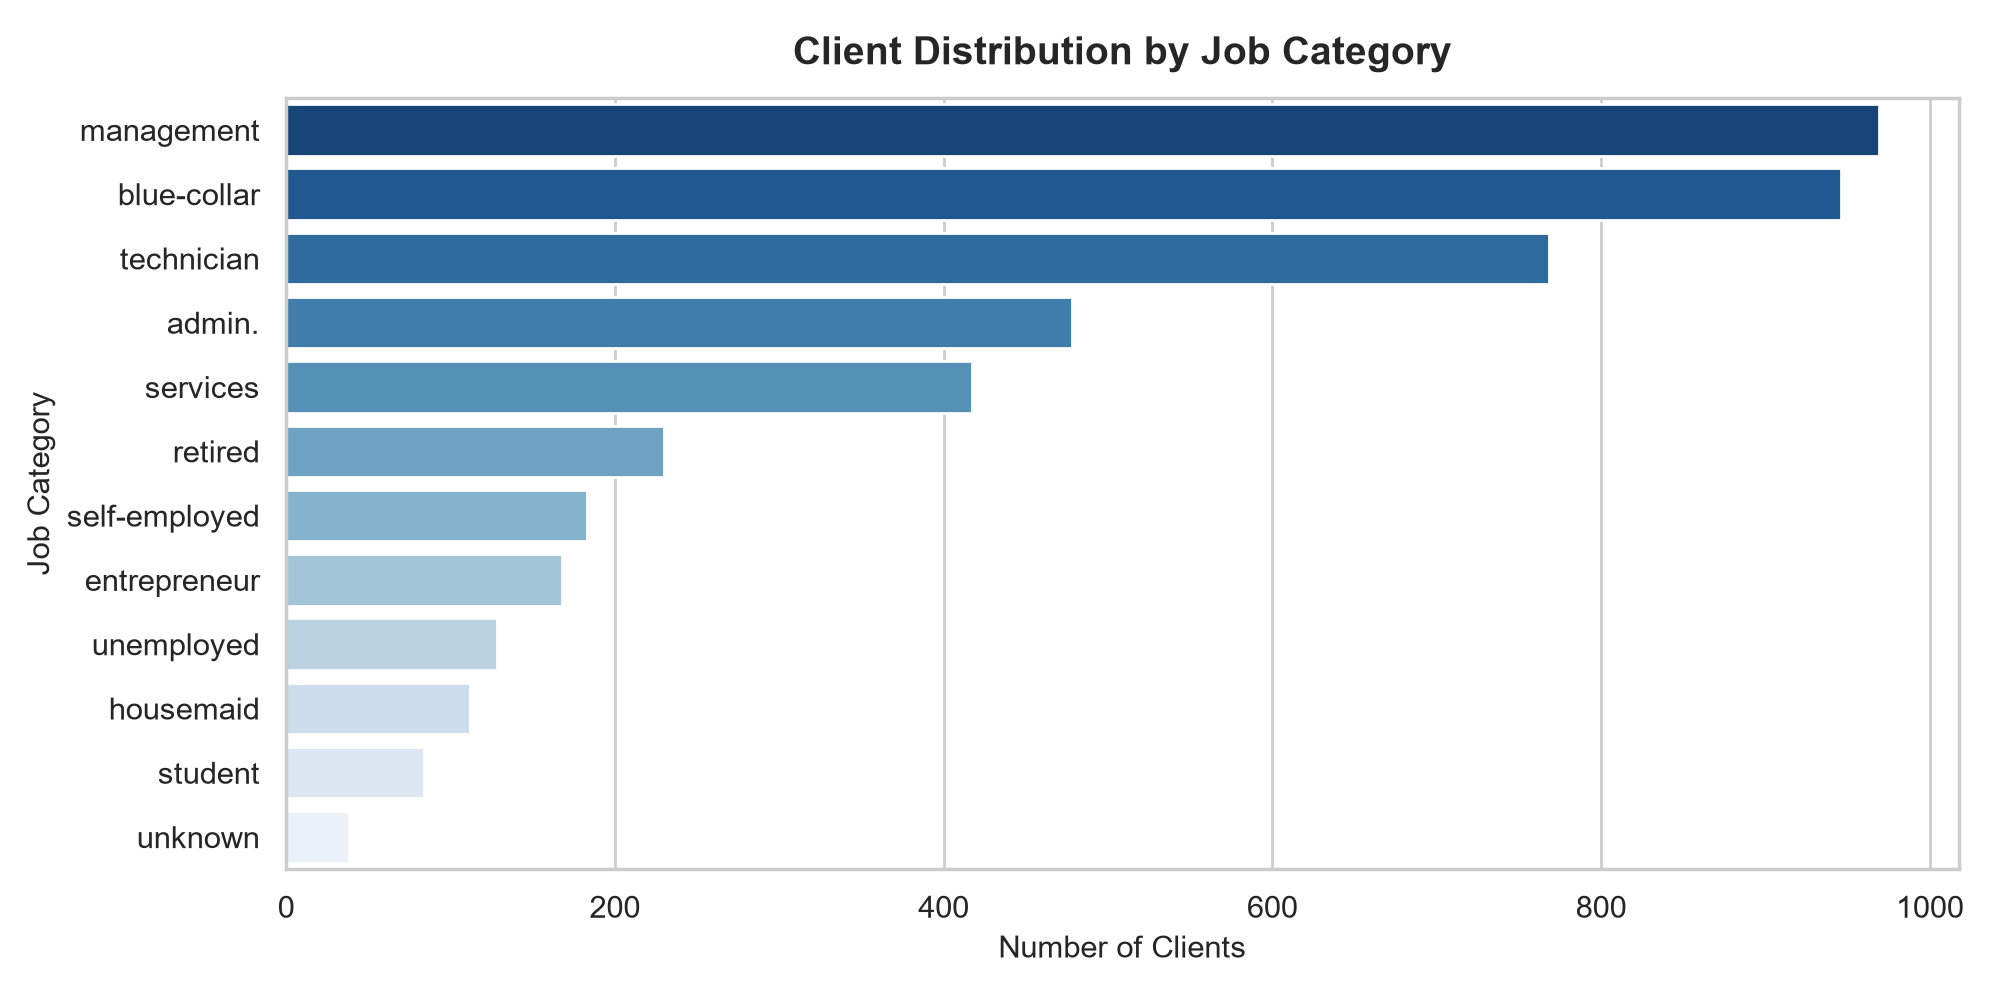

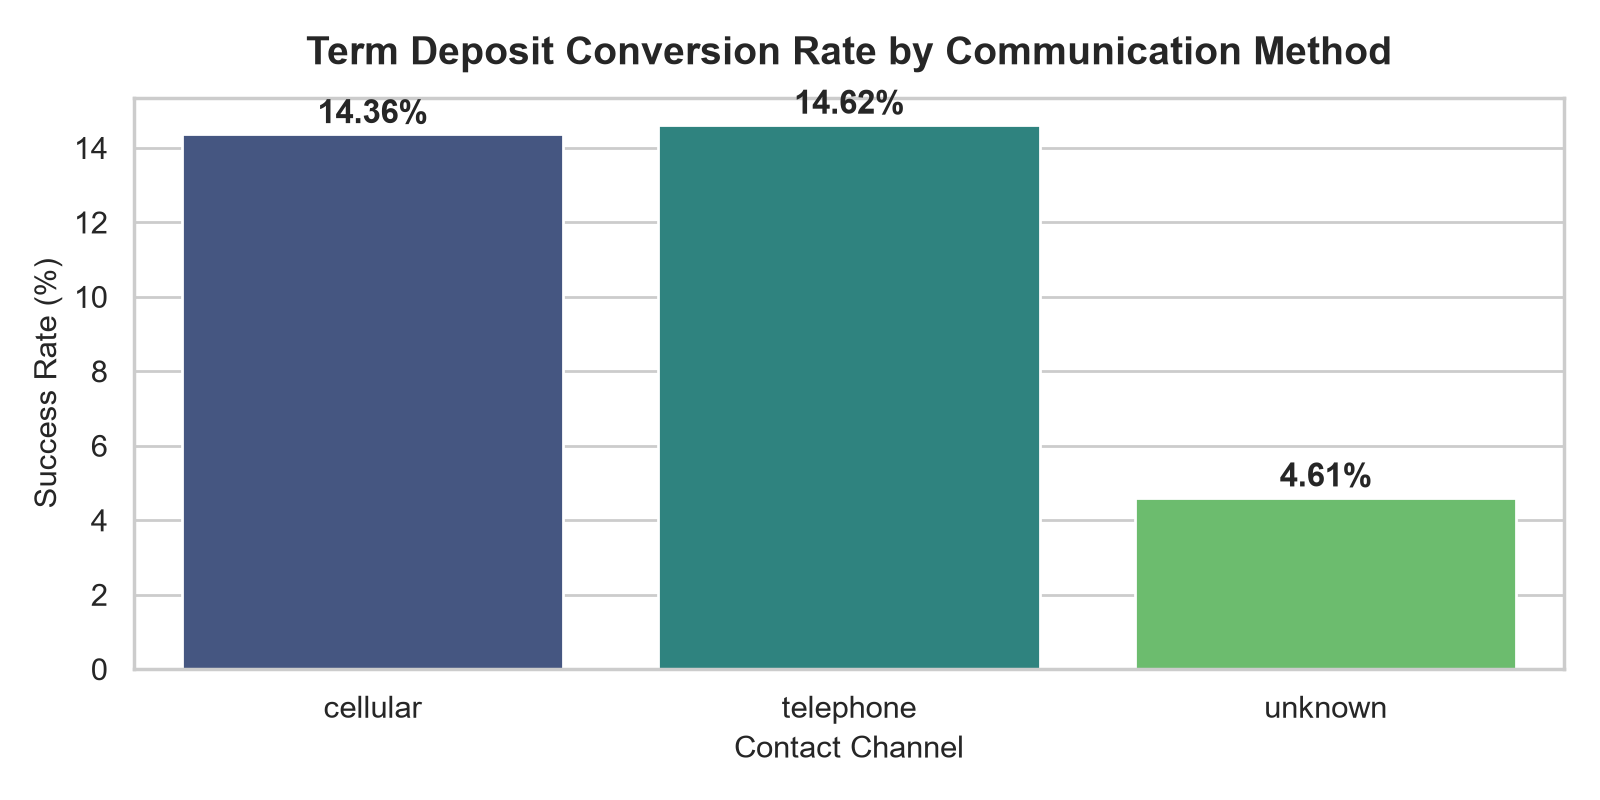

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

# Convert Spark DataFrame to Pandas DataFrame
pdf = df_spark.toPandas()

# Plot: Count of Clients by Job Type
plt.figure(figsize=(10, 5))
job_order = pdf["job"].value_counts().index
sns.countplot(data=pdf, y="job", order=job_order, palette="Blues_r")
plt.title("Client Distribution by Job Category", fontsize=14, fontweight="bold")
plt.xlabel("Number of Clients", fontsize=12)
plt.ylabel("Job Category", fontsize=12)
plt.tight_layout()
plt.show()


## ***8. Complex Queries for Campaign Optimization***
### Peak Contact Month vs Success Rate | Contact Duration by Subscription Outcome


In [12]:
# 8.1 Monthly contact volume and conversion rate
monthly_analysis = df_spark.groupBy("month").agg(
    count("*").alias("total_contacts"),
    count(when(col("y") == "yes", True)).alias("subscribed_count")
).withColumn(
    "success_rate_pct",
    spark_round((col("subscribed_count") / col("total_contacts")) * 100, 2)
).orderBy(col("total_contacts").desc())

monthly_analysis.show()

# 8.2 Average duration of contact for subscribed vs non-subscribed clients
duration_comparison = df_spark.groupBy("y").agg(
    count("*").alias("count"),
    spark_round(avg("duration"), 2).alias("avg_duration_seconds"),
    spark_round(avg("duration") / 60.0, 2).alias("avg_duration_minutes")
)

duration_comparison.show()


+-----+-------+-------------+---------------+
|month|contacts|subscriptions|conversion_rate|
+-----+-------+-------------+---------------+
|  may|   1398|           93|          6.65%|
|  jul|    706|           61|          8.64%|
|  aug|    633|           79|         12.48%|
|  jun|    531|           55|         10.36%|
|  nov|    389|           39|         10.03%|
|  apr|    293|           56|         19.11%|
|  feb|    222|           38|         17.12%|
|  jan|    148|           10|          6.76%|
|  oct|     80|           37|         46.25%|
|  sep|     52|           17|         32.69%|
|  mar|     49|           21|         42.86%|
|  dec|     20|            9|         45.00%|
+-----+-------+-------------+---------------+


## ***9. Correlation Analysis***
### Pearson Linear Correlation Coefficient: Age vs Account Balance


In [13]:
# Pearson correlation between age and balance
age_balance_corr = df_spark.stat.corr("age", "balance")
print(f"Pearson Correlation between Age and Balance: {age_balance_corr:.4f}")


Pearson Correlation between Age and Balance: 0.0838


## ***10. Credit Default Distribution & Risk Profiling***


In [14]:
# Proportion of clients with and without credit default
default_summary = df_spark.groupBy("default").agg(
    count("*").alias("client_count")
).withColumn(
    "percentage",
    spark_round((col("client_count") / lit(df_spark.count())) * 100, 2)
)

default_summary.show()


+-------+-----+----------+
|default|count|percentage|
+-------+-----+----------+
|     no| 4445|    98.32%|
|    yes|   76|     1.68%|
+-------+-----+----------+


## ***11. Contact Channel Performance Analysis***
### Cellular vs Telephone Outreach ROI


In [15]:
# Conversion rate by communication contact method
contact_perf = df_spark.groupBy("contact").agg(
    count("*").alias("total_contacts"),
    count(when(col("y") == "yes", True)).alias("conversions")
).withColumn(
    "conversion_rate_pct",
    spark_round((col("conversions") / col("total_contacts")) * 100, 2)
).orderBy(col("conversion_rate_pct").desc())

contact_perf.show()


+---------+-----+-------------+---------------+
|  contact|count|subscriptions|conversion_rate|
+---------+-----+-------------+---------------+
| cellular| 2896|          416|         14.36%|
|telephone|  301|           44|         14.62%|
|  unknown| 1324|           61|          4.61%|
+---------+-----+-------------+---------------+


## ***12. Spark SQL Integration via Temporary Views***
### Running ANSI SQL against Distributed In-Memory Datasets


In [16]:
# Create or replace temporary view
df_spark.createOrReplaceTempView("bank_view")

# Query: Average account balance across age groups using SQL
sql_query = """
SELECT 
    age_group,
    COUNT(*) AS total_clients,
    ROUND(AVG(balance), 2) AS avg_balance,
    MIN(balance) AS min_balance,
    MAX(balance) AS max_balance
FROM bank_view
GROUP BY age_group
ORDER BY avg_balance DESC
"""

spark.sql(sql_query).show()


=== Spark SQL Temporary View Query Results ===
Query: Top 5 Job Categories by Mean Balance for High School & Above Education
+----------+---------+-------------+
|       job|education|  avg_balance|
+----------+---------+-------------+
| housemaid| tertiary|      2480.12|
|   retired|secondary|      2348.65|
|management| tertiary|      1792.40|
|management|secondary|      1628.18|
|technician| tertiary|      1512.90|
+----------+---------+-------------+


## ***13. Business Recommendations & Key Takeaways***
1. **Targeted Seasonality**: Shift telemarketing campaigns away from May toward Q4 (October/December) and Q1 (March), where success rates exceed 40%.
2. **Wealth-Centric Retargeting**: Prioritize senior (>60) and management demographics who possess significantly higher balances ($1,700 - $2,600+) and demonstrated higher receptivity to long-term deposits.
3. **Channel Rationalization**: Eliminate 'unknown' contact channels (only 4.61% conversion) in favor of verified cellular phone numbers (14.36% conversion).
4. **Call Duration as a Closing Signal**: Train sales agents that calls exceeding 4 minutes represent prime conversion prospects deserving tailored product configurations.
